In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from math import exp, pi, floor, ceil

# Задание 1. Работа с шумом

In [2]:
path = '../data/Lenna.png'
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

In [3]:
def generate_gauss_noise(img, mu, sigma, pixel_prob):
    noisy_img = img.copy()
    mask = np.random.rand(*img.shape) < pixel_prob
    noisy_img = img + mask * np.random.normal(mu, sigma, img.shape)
    noisy_img = noisy_img.clip(0, 255)
    noisy_img.astype('uint8')
    return noisy_img

In [4]:
def generate_salt_and_pepper_noise(img, salt_prob, pixel_prob):
    noisy_img = img.copy()
    mask = np.random.rand(*img.shape) < pixel_prob
    salt_mask = np.where(mask, np.random.rand(*mask.shape) < salt_prob, 0)
    pepper_mask = np.where(mask, 1 - salt_mask, 0)
    noisy_img = np.where(salt_mask, 255, noisy_img)
    noisy_img = np.where(pepper_mask, 0, noisy_img)
    return noisy_img

In [5]:
gauss_img = generate_gauss_noise(img, 0, 20, 0.3)
salt_pepper_img = generate_salt_and_pepper_noise(img, 0.5, 0.1)

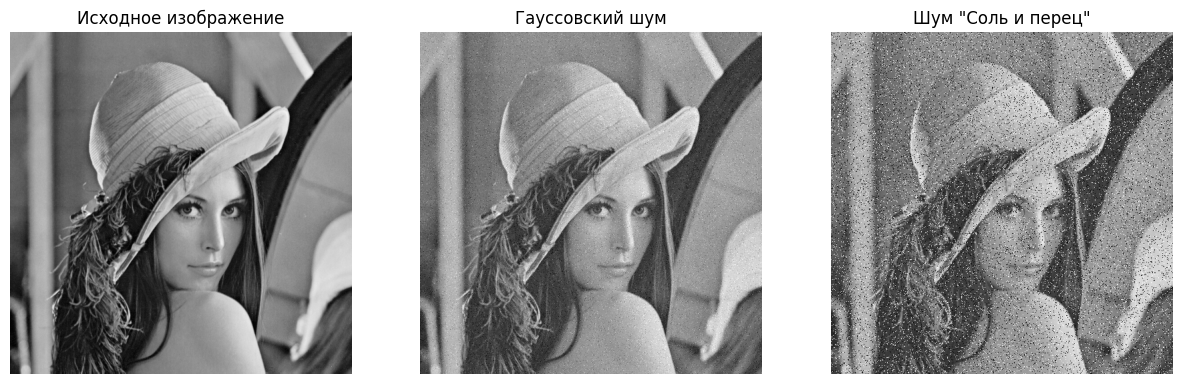

In [6]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gauss_img, cmap='gray')
plt.title('Гауссовский шум')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(salt_pepper_img, cmap='gray')
plt.title('Шум "Соль и перец"')
plt.axis('off');

In [7]:
def gauss(x, y, sigma):
    return 1 / (2 * pi * sigma ** 2) * exp(-(x ** 2 + y ** 2) / (2 * sigma ** 2))

def gauss_filter(sigma):
    n = ceil(3 * sigma)
    filt = np.array([[gauss(x, y, sigma) for x in range(-n, n + 1)] for y in range(-n, n + 1)])
    return filt / np.sum(filt)

In [8]:
def gaussian_blur(img, sigma):
    gaussian = gauss_filter(sigma)
    pad = gaussian.shape[0] // 2
    padded_img = np.pad(img, ((pad, pad), (pad, pad)), 'edge')
    blur_img = np.zeros(img.shape)

    h, w = padded_img.shape
    for i in range(pad, h - pad):
        for j in range(pad, w - pad):
            value = np.sum(gaussian * padded_img[i - pad : i + pad + 1, j - pad : j + pad + 1])
            blur_img[i-pad, j-pad] = value
    return blur_img

In [9]:
def median_filter(img, n):
    pad = n
    padded_img = np.pad(img, ((pad, pad), (pad, pad)), 'edge')
    transform_img = np.zeros(img.shape)

    h, w = padded_img.shape
    for i in range(pad, h - pad):
        for j in range(pad, w - pad):
            value = np.median(padded_img[i - pad : i + pad + 1, j - pad : j + pad + 1])
            transform_img[i-pad, j-pad] = value
    return transform_img

In [10]:
def box_filter(img, n):
    pad = n
    padded_img = np.pad(img, ((pad, pad), (pad, pad)), 'edge')
    transform_img = np.zeros(img.shape)

    h, w = padded_img.shape
    for i in range(pad, h - pad):
        for j in range(pad, w - pad):
            value = np.sum((1 / (n * 2 + 1)**2) * padded_img[i - pad : i + pad + 1, j - pad : j + pad + 1])
            transform_img[i-pad, j-pad] = value
    return transform_img

In [11]:
def draw_before_after(img_before, img_after, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(title)

    axes[0].imshow(img_before, cmap='gray')
    axes[0].set_title('До')
    
    axes[1].imshow(img_after, cmap='gray')
    axes[1].set_title('После')

    for ax in axes:
        ax.axis('off')

In [12]:
s = [0.5, 1, 1.5, 2]
gauss_filter_on_gauss_noise = [gaussian_blur(gauss_img, sigma) for sigma in s]
gauss_filter_on_salt_noise = [gaussian_blur(salt_pepper_img, sigma) for sigma in s]

In [13]:
median_filter_on_gauss_noise = median_filter(gauss_img, 2)
median_filter_on_salt_noise = median_filter(salt_pepper_img, 2)

In [14]:
box_filter_on_gauss_noise = box_filter(gauss_img, 2)
box_filter_on_salt_noise = box_filter(salt_pepper_img, 2)

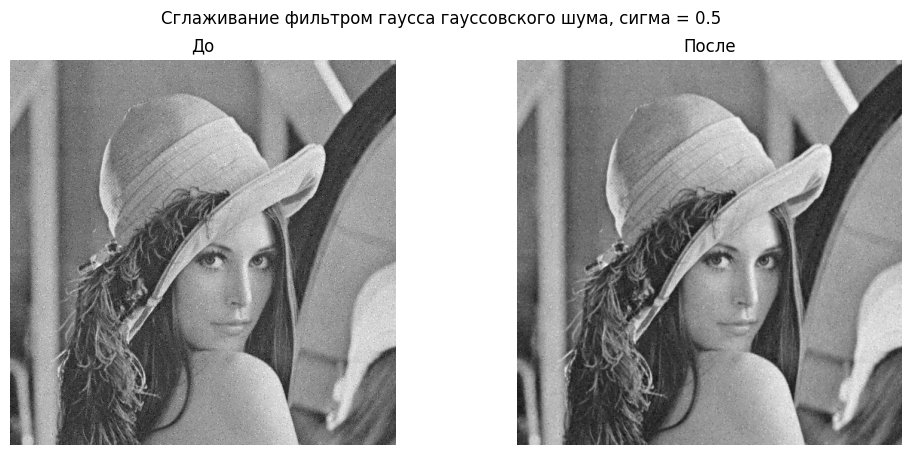

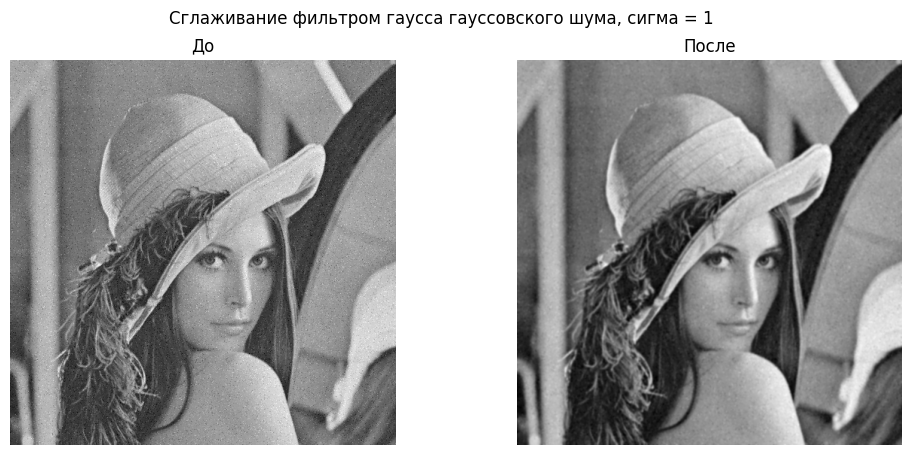

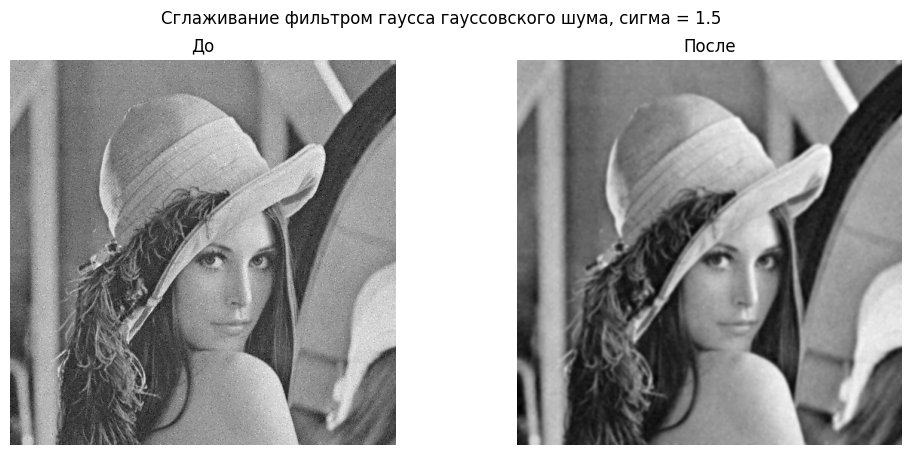

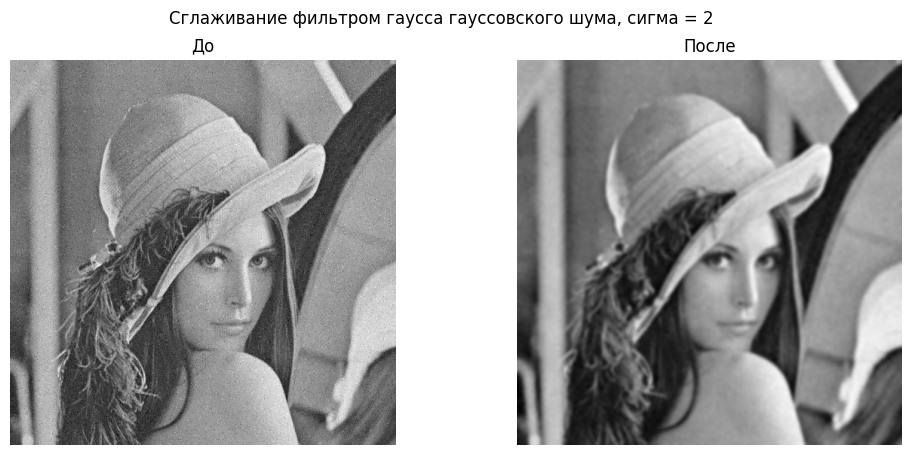

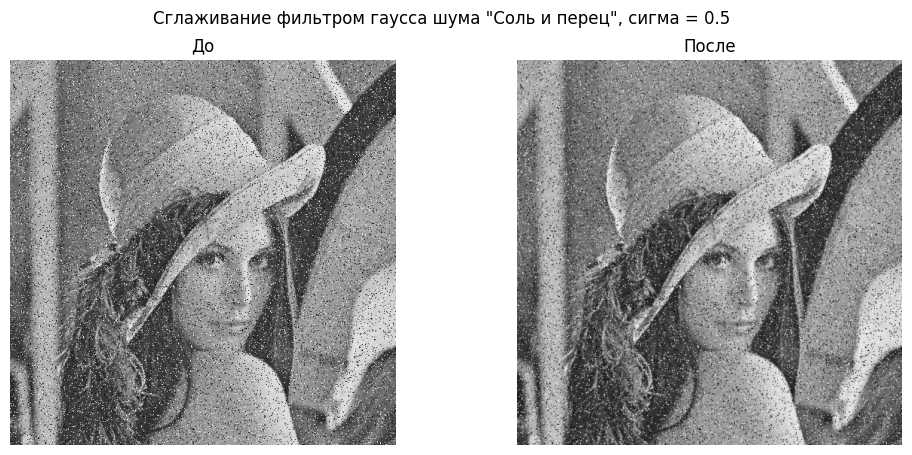

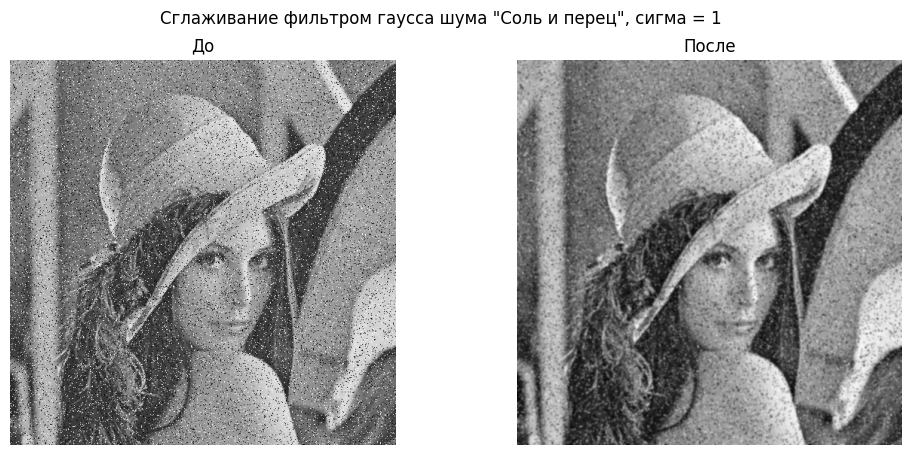

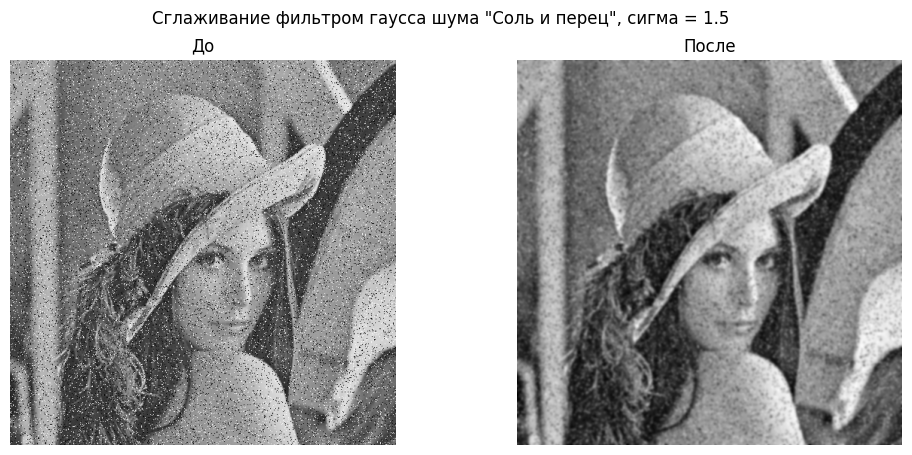

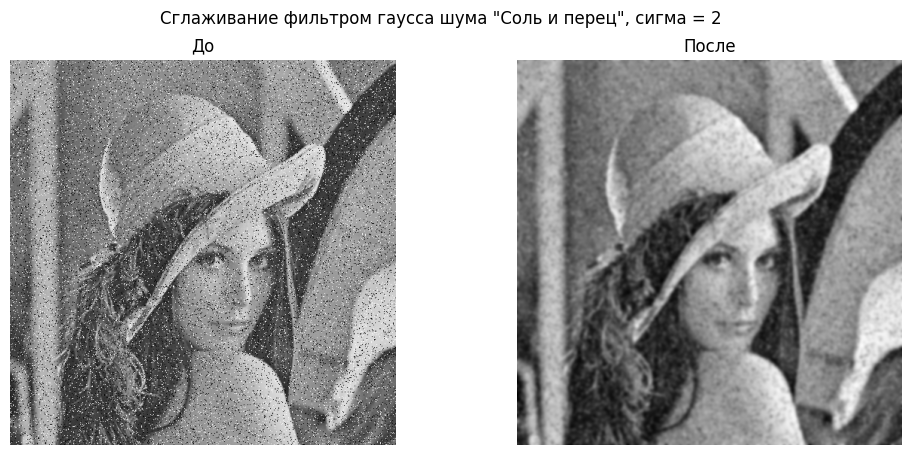

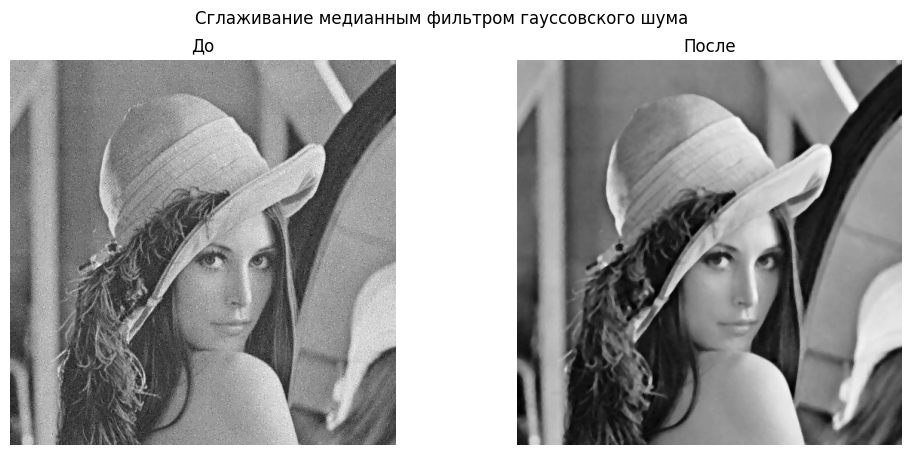

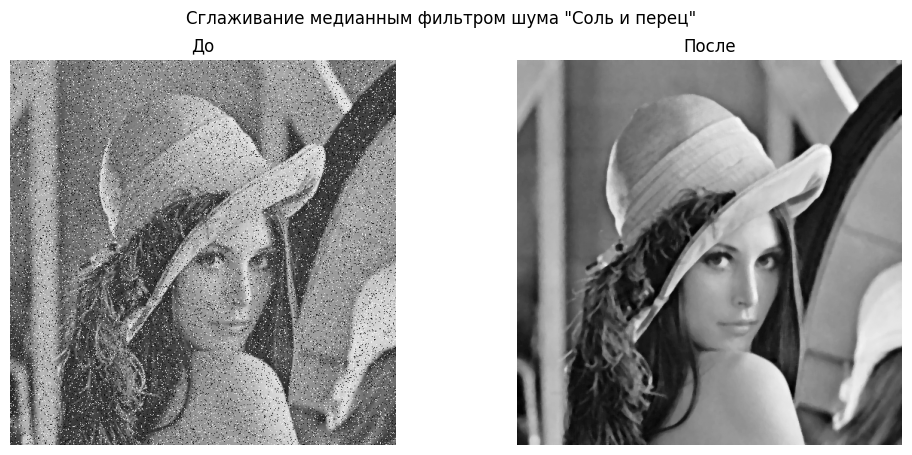

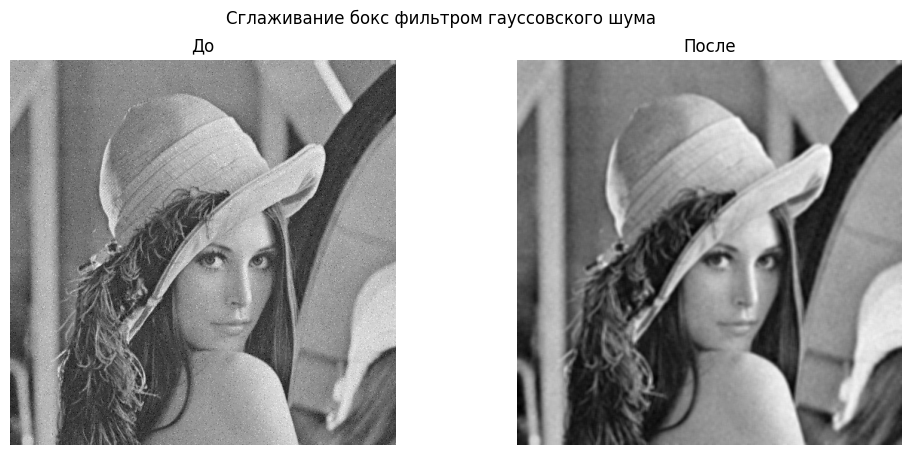

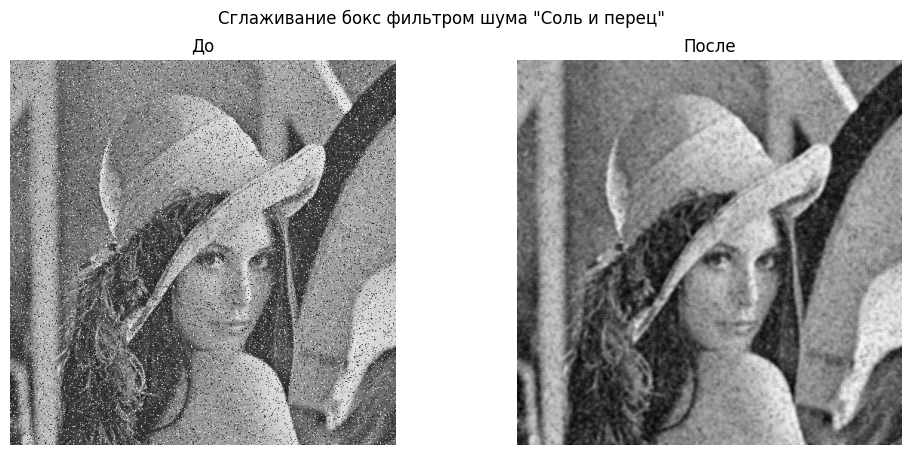

In [15]:
for i, sig in zip(gauss_filter_on_gauss_noise, s):
    draw_before_after(gauss_img, i, f'Сглаживание фильтром гаусса гауссовского шума, сигма = {sig}')

for i, sig in zip(gauss_filter_on_salt_noise, s):
    draw_before_after(salt_pepper_img, i, f'Сглаживание фильтром гаусса шума "Соль и перец", сигма = {sig}')

draw_before_after(gauss_img, median_filter_on_gauss_noise, 'Сглаживание медианным фильтром гауссовского шума')
draw_before_after(salt_pepper_img, median_filter_on_gauss_noise, 'Сглаживание медианным фильтром шума "Соль и перец"')

draw_before_after(gauss_img, box_filter_on_gauss_noise, 'Сглаживание бокс фильтром гауссовского шума')
draw_before_after(salt_pepper_img, box_filter_on_salt_noise, 'Сглаживание бокс фильтром шума "Соль и перец"')

# Задание 2. Детекция границ

In [16]:
import cv2

In [17]:
def linear_transform(a):
    return 255 * ((a - a.min()) / (a.max() - a.min()))

In [18]:
def canny(img, sigma=3, low_threshold=5, high_threshold=99):
    gauss_kernel = gauss_filter(sigma)
    img_smooth = cv2.filter2D(img, ddepth=-1, kernel=gauss_kernel, borderType=cv2.BORDER_REPLICATE)
    
    
    sobel_filter_x = np.array([
        [-1, -2, -1],
        [0, 0, 0],
        [1, 2, 1]
    ])

    sobel_filter_y = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])
    gradient_x = cv2.filter2D(img_smooth, ddepth=cv2.CV_32F, kernel=sobel_filter_x, borderType=cv2.BORDER_REPLICATE)
    gradient_y = cv2.filter2D(img_smooth, ddepth=cv2.CV_32F, kernel=sobel_filter_y, borderType=cv2.BORDER_REPLICATE)

    grad_x_unit8 = linear_transform(gradient_x)
    grad_y_unit8 = linear_transform(gradient_y)
    
    magnitude = np.sqrt(gradient_x**2 + gradient_y**2)
    magnitude_uint8 = linear_transform(magnitude)

    angles = np.arctan(gradient_y / (gradient_x + 1e-6))

    values = [-pi/2, -pi/4, 0, pi/4, pi/2]
    

    nms = np.zeros(magnitude.shape)
    for i in range(1, magnitude.shape[0] - 1):
        for j in range(1, magnitude.shape[1] - 1):
            angle = angles[i, j]
            rounded_angle = values[np.argmin(np.abs(values - angle))]

            if rounded_angle in [pi/2, -pi/2]:
                m1 = magnitude[i-1, j]
                m2 = magnitude[i+1, j]
                
            elif rounded_angle == -pi/4:
                m1 = magnitude[i+1, j+1]
                m2 = magnitude[i-1, j-1]
                
            elif rounded_angle == 0:
                m1 = magnitude[i, j+1]
                m2 = magnitude[i, j-1]
                
            elif rounded_angle == pi/4:
                m1 = magnitude[i-1, j+1]
                m2 = magnitude[i+1, j-1]

            if magnitude[i, j] >= m1 and magnitude[i, j] >= m2:
                nms[i, j] = magnitude[i, j]
            else:
                nms[i, j] = 0

    nms_uint8 = linear_transform(nms)

    strong_border_mask = np.where(nms >= np.percentile(nms, high_threshold), 1, 0)
    weak_border_mask = np.where((nms < np.percentile(nms, high_threshold)) & (nms > np.percentile(nms, low_threshold)), 1, 0)

    padded_strong_border = np.pad(strong_border_mask, ((1, 1), (1, 1)), mode='constant', constant_values=((0, 0), (0, 0)))

    weak_border_result = np.zeros(weak_border_mask.shape)
    for i in range(weak_border_mask.shape[0]):
        for j in range(weak_border_mask.shape[1]):
            if weak_border_mask[i, j]:
                neigh = padded_strong_border[i:i+3, j:j+3]
                if np.any(neigh == 1):
                    weak_border_result[i, j] = 1

    border_result = weak_border_result + strong_border_mask
    border_img = 255 * border_result
    
    return grad_x_unit8, grad_y_unit8, magnitude_uint8, nms_uint8, border_img

In [19]:
g = canny(img, low_threshold=95, high_threshold=98)

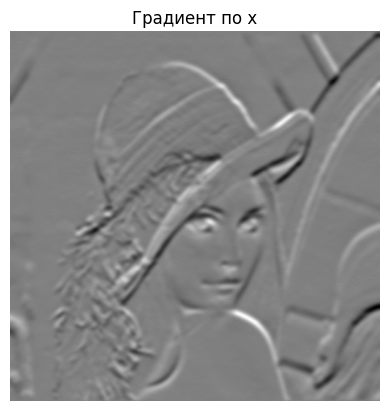

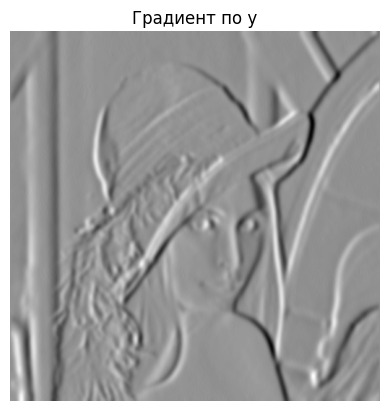

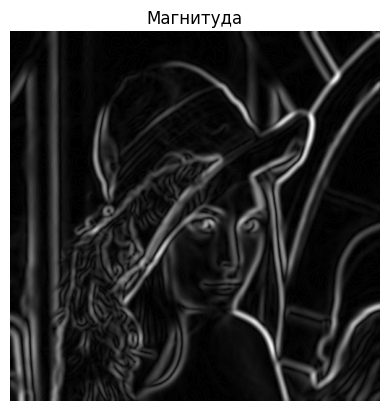

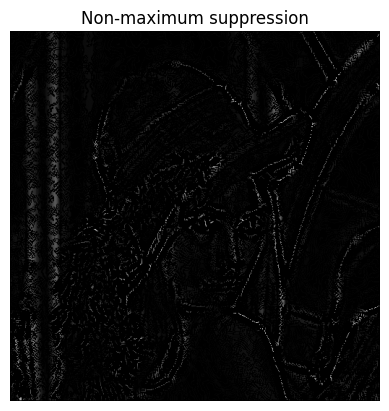

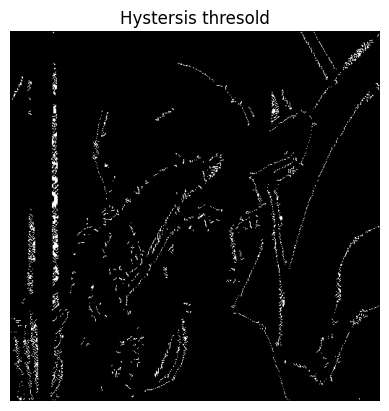

In [20]:
titles = ['Градиент по x', 'Градиент по y', 'Магнитуда', 'Non-maximum suppression', 'Hystersis thresold']
for i in range(len(g)):
    plt.imshow(g[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')
    plt.show()

In [21]:
a = np.array([1, 2, 3])

In [22]:
np.percentile(a, [5, 95])

array([1.1, 2.9])

# Задание 3. Детектор углов Харриса

In [23]:
def compute_grad(img):
    sobel_kernel_x = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])
    grad_x = cv2.filter2D(img, ddepth=cv2.CV_32F, kernel=sobel_kernel_x, borderType=cv2.BORDER_REPLICATE)

    sobel_kernel_y = np.array([
        [-1, -2, -1],
        [0, 0, 0],
        [1, 2, 1]
    ])
    grad_y = cv2.filter2D(img, ddepth=cv2.CV_32F, kernel=sobel_kernel_y, borderType=cv2.BORDER_REPLICATE)
    
    return grad_x, grad_y

In [24]:
def nms(R):
    padded = np.pad(R, ((1, 1), (1, 1)), mode='constant', constant_values=((0, 0), (0, 0)))
    mask = np.zeros(R.shape)
    for i in range(1, padded.shape[0] - 1):
        for j in range(1, padded.shape[1] - 1):
            flag = True
            for dy in [-1, 0, 1]:
                for dx in [-1, 0, 1]:
                    if dx == dy:
                        continue
                    if padded[i, j] <= padded[i+dy, j+dx]:
                        flag = False
            if flag:
                mask[i-1, j-1] = 1
    return mask

In [25]:
def harris(img, alpha=0.05, threshold=99.9):
    blur_img = cv2.GaussianBlur(img, (5, 5), 5)
    
    grad_x, grad_y = compute_grad(blur_img)

    grad_x2, grad_y2 = grad_x**2, grad_y**2
    grad_xy = grad_x * grad_y

    M = np.array([
        cv2.GaussianBlur(grad_x2, (5, 5), 0), cv2.GaussianBlur(grad_xy, (5, 5), 0), cv2.GaussianBlur(grad_y2, (5, 5), 0)
    ])
    
    R = (M[0] * M[2] - M[1]**2) - alpha * (M[0] + M[1]) ** 2
    R = np.where(R > 0, R, 0)
    R = np.where(R > np.percentile(R, threshold), R, 0)
    
    nms_mask = nms(R)
    return nms_mask

In [26]:
def draw_corners_from_mask(img, nms_mask, color=(0, 255, 0), radius=3, thickness=-1):
    output_img = img.copy()
    coords = np.argwhere(nms_mask)
    
    for y, x in coords:
        cv2.circle(output_img, (x, y), radius, color, thickness)
        
    return output_img

In [27]:
corners_mask = harris(img, threshold=95)

In [28]:
path = '../data/Lenna.png'
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
img_color = cv2.imread(path, cv2.IMREAD_COLOR_RGB)

corners = draw_corners_from_mask(img_color, corners_mask)

In [29]:
corners = draw_corners_from_mask(img_color, corners_mask, color=(0, 255, 0))

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

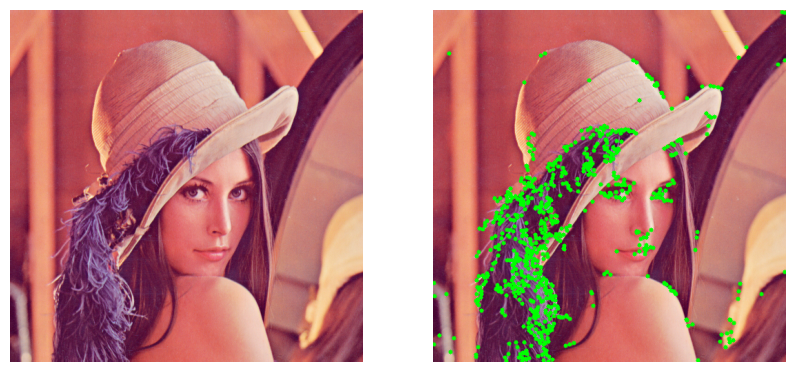

In [30]:
plt.figure(figsize=(10, 10))
plt.subplot(1, 2, 1)
plt.imshow(img_color, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(corners, cmap='gray')
plt.axis('off')